In [1]:
import io, os, urllib.request
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

SRC = "upload"
METHOD = "kmeans"
K, BLUR, INVERT = 4, 1.0, False
SE_SIZE, SE_SHAPE = 5, "disk"
MIN_AREA, WINDOW, MAX_SIZE = None, None, 512
OUT = "results"

In [2]:
EXT = (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff", ".gif", ".webp")

def to_gray(img):
    if img.ndim == 3: img = img[..., :3] @ [.299, .587, .114]
    img = img.astype(float)
    if img.max() <= 1: img *= 255
    return img.clip(0, 255).astype(np.uint8)

def load_rgb(src): return np.array(Image.open(src).convert("RGB"))

def downscale(img, m):
    h, w = img.shape[:2]
    s = max(h, w) / m if m > 0 else 1
    if s <= 1: return img
    return img[np.ix_((np.arange(int(h / s)) * s).astype(int), (np.arange(int(w / s)) * s).astype(int))]

def synthetic(n=256, seed=0):
    r = np.random.default_rng(seed)
    y, x = np.mgrid[:n, :n]
    gt = (((y-70)**2 + (x-80)**2 < 1600) | ((abs(y-170) < 35) & (abs(x-90) < 50))
          | ((y-150)**2 + (x-190)**2 < 1225) | ((abs(y-60) < 12) & (abs(x-200) < 40)))
    img = np.where(gt, 170., 80.) + r.normal(0, 28, (n, n))
    s = r.random((n, n))
    img[s < .03], img[s > .97] = 255, 0
    return img.clip(0, 255).astype(np.uint8), gt

def gather(src):
    out = []
    for s in [src] if isinstance(src, str) else src:
        s = os.path.expanduser(s.strip().strip("\"'"))
        if s == "demo": out.append(("demo", None))
        elif s == "upload":
            from google.colab import files
            out += [(n, io.BytesIO(b)) for n, b in files.upload().items()]
        elif s.startswith("http"):
            req = urllib.request.Request(s, headers={"User-Agent": "Mozilla/5.0"})
            out.append((os.path.basename(s.split("?")[0]) or "url.png", io.BytesIO(urllib.request.urlopen(req).read())))
        elif os.path.isdir(s):
            out += [(f, os.path.join(s, f)) for f in sorted(os.listdir(s)) if f.lower().endswith(EXT)]
        elif os.path.isfile(s): out.append((os.path.basename(s), s))
        else: print("skip:", s)
    return out

In [3]:
def blur(img, s):
    if s <= 0: return img
    r = max(1, int(3 * s))
    x = np.arange(-r, r + 1)
    k = np.exp(-x**2 / (2 * s**2)); k /= k.sum()
    f = img.astype(float)
    for ax in (0, 1):
        pad = [(0, 0)] * f.ndim; pad[ax] = (r, r)
        p, n = np.pad(f, pad, mode="reflect"), f.shape[ax]
        f = sum(kv * p[tuple(slice(i, i + n) if a == ax else slice(None) for a in range(f.ndim))]
                for i, kv in enumerate(k))
    return f

In [4]:
def otsu(g):
    p = np.bincount(g.ravel(), minlength=256) / g.size
    w, m = p.cumsum(), (p * np.arange(256)).cumsum()
    with np.errstate(all="ignore"): s = (m[-1] * w - m)**2 / (w * (1 - w))
    return int(np.argmax(np.nan_to_num(s)))

def sauvola(gray, win, k=.2, R=128.):
    g = gray.astype(float)
    h, w = g.shape
    p = np.pad(g, win // 2, mode="reflect")
    def box(a):
        ii = np.zeros((a.shape[0] + 1, a.shape[1] + 1)); ii[1:, 1:] = a.cumsum(0).cumsum(1)
        return (ii[win:win+h, win:win+w] - ii[:h, win:win+w] - ii[win:win+h, :w] + ii[:h, :w]) / win**2
    m = box(p); sd = np.sqrt(np.maximum(box(p * p) - m**2, 0))
    return g < m * (1 + k * (sd / R - 1))

In [5]:
def rgb2lab(rgb):
    c = rgb / 255.
    lin = np.where(c > .04045, ((c + .055) / 1.055)**2.4, c / 12.92)
    M = np.array([[.4124564, .3575761, .1804375], [.2126729, .7151522, .072175], [.0193339, .119192, .9503041]])
    x = lin @ M.T / [.95047, 1, 1.08883]
    f = np.where(x > .008856, np.cbrt(x), 7.787 * x + 16 / 116)
    return np.stack([116 * f[..., 1] - 16, 500 * (f[..., 0] - f[..., 1]), 200 * (f[..., 1] - f[..., 2])], -1)

def sqd(X, C): return (X**2).sum(1)[:, None] - 2 * X @ C.T + (C**2).sum(1)

def kmeans(X, k, iters=30, seed=0, n=30000):
    rng = np.random.default_rng(seed)
    S = X if len(X) <= n else X[rng.choice(len(X), n, replace=False)]
    C = [S[rng.integers(len(S))]]
    for _ in range(1, k):
        d = np.maximum(sqd(S, np.array(C)).min(1), 0)
        C.append(S[rng.choice(len(S), p=d / d.sum())] if d.sum() > 0 else S[rng.integers(len(S))])
    C = np.array(C)
    for _ in range(iters):
        lab, new = sqd(S, C).argmin(1), C.copy()
        for j in range(k):
            new[j] = S[lab == j].mean(0) if (lab == j).any() else S[sqd(S, C).min(1).argmax()]
        done, C = np.allclose(new, C, atol=1e-3), new
        if done: break
    step = 200000
    return C, np.concatenate([sqd(X[i:i+step], C).argmin(1) for i in range(0, len(X), step)]).astype(np.int32)

def seg_kmeans(rgb, k):
    lab = rgb2lab(rgb)
    C, l = kmeans(lab.reshape(-1, 3), k)
    remap = np.empty(k, np.int32); remap[C[:, 0].argsort()] = np.arange(k)
    return remap[l].reshape(lab.shape[:2])

In [6]:
def kernel(n=3, shape="square"):
    r = n // 2
    y, x = np.mgrid[-r:r+1, -r:r+1]
    return {"square": np.ones((n, n), bool), "disk": y**2 + x**2 <= r**2, "cross": (y == 0) | (x == 0)}[shape]

def _morph(m, k, op, init):
    ry, rx = k.shape[0] // 2, k.shape[1] // 2
    p, (h, w), out = np.pad(m, ((ry, ry), (rx, rx))), m.shape, np.full_like(m, init)
    for i, j in zip(*np.nonzero(k)): out = op(out, p[i:i+h, j:j+w])
    return out

dilate  = lambda m, k: _morph(m, k, np.logical_or, False)
erode   = lambda m, k: _morph(m, k, np.logical_and, True)
opening = lambda m, k: dilate(erode(m, k), k)
closing = lambda m, k: erode(dilate(m, k), k)

In [7]:
def label(mask, conn=8):
    h, w = mask.shape
    W = w + 2
    pad = np.zeros((h + 2, W), bool); pad[1:-1, 1:-1] = mask
    flat, lab = pad.ravel().tolist(), [0] * ((h + 2) * W)
    offs = [-W, -1, 1, W] if conn == 4 else [-W-1, -W, -W+1, -1, 1, W-1, W, W+1]
    ys, xs = np.nonzero(mask)
    sizes, n = [], 0
    for s in ((ys + 1) * W + xs + 1).tolist():
        if lab[s]: continue
        n += 1; lab[s] = n
        st, cnt = [s], 0
        while st:
            p = st.pop(); cnt += 1
            for o in offs:
                q = p + o
                if flat[q] and not lab[q]: lab[q] = n; st.append(q)
        sizes.append(cnt)
    return np.array(lab, np.int32).reshape(h + 2, W)[1:-1, 1:-1], n, np.array(sizes, np.int64)

def remove_small(m, a):
    if a <= 1: return m
    L, n, s = label(m)
    return np.r_[False, s >= a][L]

def clean_binary(m, k, a):
    return ~remove_small(~remove_small(closing(opening(m, k), k), a), a)

def fill(l, k):
    l = l.copy()
    h, w = l.shape
    for _ in range(300):
        un = l < 0
        if not un.any(): break
        cnt = np.zeros((k, h, w), np.int32)
        for c in range(k):
            p = np.pad(l == c, 1)
            for dy in range(3):
                for dx in range(3): cnt[c] += p[dy:dy+h, dx:dx+w]
        f = un & (cnt.sum(0) > 0)
        if not f.any(): l[un] = 0; break
        l[f] = cnt.argmax(0)[f]
    return l

def clean_labels(l, k, se, a):
    claims = np.stack([closing(opening(l == c, se), se) for c in range(k)])
    out = np.where(claims.sum(0) == 1, claims.argmax(0), -1)
    ok = np.take_along_axis(claims, l[None], 0)[0]
    out = fill(np.where((out < 0) & ok, l, out), k)
    for c in range(k):
        L, n, s = label(out == c)
        if n: out[np.r_[False, s < a][L]] = -1
    return fill(out, k)

In [8]:
def iou(p, g):
    u = (p | g).sum()
    return (p & g).sum() / u if u else 1.

def dice(p, g):
    s = p.sum() + g.sum()
    return 2 * (p & g).sum() / s if s else 1.

def stats(m, a):
    _, n, s = label(m)
    return n, int((s < a).sum())

def region_stats(l, k, a):
    st = [stats(l == c, a) for c in range(k)]
    e = np.zeros(l.shape, bool)
    e[:, :-1] |= l[:, :-1] != l[:, 1:]; e[:-1] |= l[:-1] != l[1:]
    return sum(n for n, _ in st), sum(t for _, t in st), e.mean()

def paint(l, rgb, k):
    out = np.zeros(l.shape + (3,), np.uint8)
    for c in range(k):
        if (l == c).any(): out[l == c] = rgb[l == c].mean(0)
    return out

In [9]:
fmt = lambda x: f"{int(x):>10,}" if float(x).is_integer() else f"{x:>10.4f}"

def run(name, rgb, gt=None, method=None):
    method = method or METHOD
    h, w = rgb.shape[:2]
    a = MIN_AREA if MIN_AREA is not None else max(4, int(5e-4 * h * w))
    se, base = kernel(SE_SIZE, SE_SHAPE), os.path.splitext(name)[0]
    os.makedirs(OUT, exist_ok=True)
    print(f"\n=== {base} ({w}x{h}) {method} SE={SE_SHAPE}{SE_SIZE} min_area={a} ===")

    if method == "kmeans":
        raw = seg_kmeans(blur(rgb, BLUR).clip(0, 255).astype(np.uint8), K)
        clean = clean_labels(raw, K, se, a)
        r0, r1 = region_stats(raw, K, a), region_stats(clean, K, a)
        rows = [("Regions", r0[0], r1[0]), ("Tiny regions", r0[1], r1[1]), ("Boundary fraction", r0[2], r1[2])]
        diff = np.full(rgb.shape, 255, np.uint8); diff[raw != clean] = (220, 30, 30)
        panels = [("Input", rgb), (f"k-means (k={K})", paint(raw, rgb, K)),
                  ("+ morphology", paint(clean, rgb, K)), ("Changed (red)", diff)]
        res = panels[2][1]
        print(f"Pixels changed: {(raw != clean).mean():.2%}")
    else:
        gray = to_gray(blur(rgb, BLUR).clip(0, 255))
        if INVERT: gray = 255 - gray
        if method == "otsu":
            t = otsu(gray); raw, ttl = gray > t, f"Otsu (t={t})"
        else:
            win = (WINDOW or max(15, min(h, w) // 8)) | 1
            raw, ttl = sauvola(255 - gray, win), f"Sauvola (win={win})"
        clean = clean_binary(raw, se, a)
        (n0, t0), (n1, t1) = stats(raw, a), stats(clean, a)
        rows = [("Components", n0, n1), ("Tiny components", t0, t1), ("Foreground px", raw.sum(), clean.sum())]
        if gt is not None: rows += [("IoU", iou(raw, gt), iou(clean, gt)), ("Dice", dice(raw, gt), dice(clean, gt))]
        panels = [("Gray", gray), (ttl, raw), ("Opening", opening(raw, se)), ("Closing", closing(raw, se)), ("Cleaned", clean)]
        if gt is not None: panels.insert(1, ("Ground truth", gt))
        res = clean.astype(np.uint8) * 255

    print(f"{'':20s}{'Raw':>10s}{'Cleaned':>10s}")
    for n, x, y in rows: print(f"{n:20s}{fmt(x)}{fmt(y)}")

    plt.imsave(f"{OUT}/{base}_segmented.png", res, cmap="gray")
    fig, axs = plt.subplots(1, len(panels), figsize=(3.6 * len(panels), 4))
    for ax, (t, im) in zip(axs, panels):
        ax.imshow(im, cmap="gray", vmin=0, vmax=255 if im.dtype == np.uint8 else 1)
        ax.set_title(t, fontsize=9); ax.axis("off")
    plt.tight_layout(); plt.savefig(f"{OUT}/{base}_comparison.png", dpi=150); plt.show()

Saving Screenshot 2026-05-03 104308.png to Screenshot 2026-05-03 104308.png

=== Screenshot 2026-05-03 104308 (512x287) kmeans SE=disk5 min_area=73 ===
Pixels changed: 2.56%
                           Raw   Cleaned
Regions                     63         9
Tiny regions                39         0
Boundary fraction       0.0433    0.0197


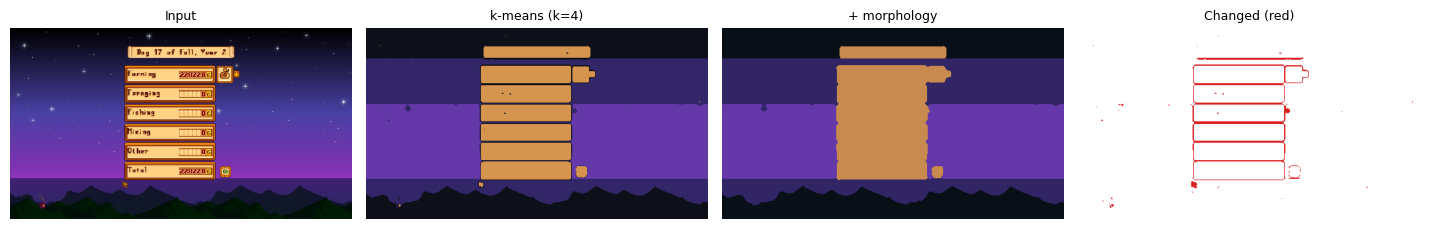

In [10]:
for name, s in gather(SRC):
    if s is None:
        g, gt = synthetic()
        run("demo", np.stack([g] * 3, -1), gt, "otsu" if METHOD == "kmeans" else METHOD)
    else: run(name, downscale(load_rgb(s), MAX_SIZE))